In [6]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    normalized_mutual_info_score,
    adjusted_rand_score
)
from sklearn.decomposition import PCA

# --- 1. Reproducibility Setup ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# --- 2. Compute Device Selection (Apple Silicon MPS / CUDA / CPU) ---
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Active Compute Device: {device}")

# --- 3. Directory Setup for Artifacts ---
ARTIFACT_DIR = "./customics_artifacts"
os.makedirs(os.path.join(ARTIFACT_DIR, "models"), exist_ok=True)
os.makedirs(os.path.join(ARTIFACT_DIR, "embeddings"), exist_ok=True)
print(f"Artifacts directory prepared at: {ARTIFACT_DIR}")
print("(64,64,64,64)->64*4->256")

Active Compute Device: mps
Artifacts directory prepared at: ./customics_artifacts
(64,64,64,64)->64*4->256


In [2]:
# Dataset directory containing the 4 omics tables and label file
DATA_DIR = "Main_Dataset/Classification_datasets/Pan-cancer/Original"

print("Loading Pan-Cancer multi-omics data tables (4 modalities)...")

# 1. Load the 4 omics modalities
mrna_df = pd.read_csv(os.path.join(DATA_DIR, "Pan-cancer_mRNA.csv"), index_col=0)
methy_df = pd.read_csv(os.path.join(DATA_DIR, "Pan-cancer_Methy.csv"), index_col=0)
cnv_df = pd.read_csv(os.path.join(DATA_DIR, "Pan-cancer_CNV.csv"), index_col=0)
mirna_df = pd.read_csv(os.path.join(DATA_DIR, "Pan-cancer_miRNA.csv"), index_col=0)

# 2. Load ground-truth cancer class labels
labels_df = pd.read_csv(os.path.join(DATA_DIR, "Pan-cancer_label_num.csv"))
label_col = labels_df.columns[-1]

# 3. Transpose matrices to (N_patients, N_features) and convert data types
X_mrna = mrna_df.T.values.astype(np.float32)
X_methy = methy_df.T.values.astype(np.float32)
X_cnv = cnv_df.T.values.astype(np.float32)
X_mirna = mirna_df.T.values.astype(np.float32)
y = labels_df[label_col].values.astype(np.int64)

# 4. Extract cohort dimensions
num_patients = len(y)
num_classes = len(np.unique(y))
mrna_dim = X_mrna.shape[1]
methy_dim = X_methy.shape[1]
cnv_dim = X_cnv.shape[1]
mirna_dim = X_mirna.shape[1]

print(f"\nCohort Size          : {num_patients} Patients across {num_classes} Distinct Primary Cancer Types")
print(f"  * mRNA Features     : {mrna_dim}")
print(f"  * Methylation Probes: {methy_dim}")
print(f"  * CNV Features      : {cnv_dim}")
print(f"  * miRNA Features    : {mirna_dim}")

Loading Pan-Cancer multi-omics data tables (4 modalities)...

Cohort Size          : 8314 Patients across 32 Distinct Primary Cancer Types
  * mRNA Features     : 3217
  * Methylation Probes: 3139
  * CNV Features      : 3105
  * miRNA Features    : 383


In [3]:
SUB_DIM = 64  # Bottleneck dimension per modality (64 x 4 = 256 total fused dims)

class SourceAutoencoder(nn.Module):
    def __init__(self, in_features, latent_dim=SUB_DIM):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, latent_dim),
            nn.BatchNorm1d(latent_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Linear(256, in_features)
        )

    def forward(self, x):
        z = self.encoder(x)
        rec = self.decoder(z)
        return z, rec


class CustOmicsPanCancerDirect(nn.Module):
    def __init__(self, mrna_dim, methy_dim, cnv_dim, mirna_dim, num_classes):
        super().__init__()
        # 1. Source-Specific Sub-Autoencoders (4 Modalities)
        self.ae_mrna = SourceAutoencoder(mrna_dim, SUB_DIM)
        self.ae_methy = SourceAutoencoder(methy_dim, SUB_DIM)
        self.ae_cnv = SourceAutoencoder(cnv_dim, SUB_DIM)
        self.ae_mirna = SourceAutoencoder(mirna_dim, SUB_DIM)

        # 2. Combined Latent Dimension: 64 * 4 = 256
        fused_in_dim = SUB_DIM * 4

        # 3. Direct Classification Head (maps 256D -> 32 Cancer Classes)
        self.classifier = nn.Sequential(
            nn.Linear(fused_in_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x_mrna, x_methy, x_cnv, x_mirna, phase=1):
        # Pass each modality through its specific autoencoder
        z_mrna, rec_mrna = self.ae_mrna(x_mrna)
        z_methy, rec_methy = self.ae_methy(x_methy)
        z_cnv, rec_cnv = self.ae_cnv(x_cnv)
        z_mirna, rec_mirna = self.ae_mirna(x_mirna)

        # Phase 1: Source-Specific Pre-training (Returns reconstruction tensors)
        if phase == 1:
            return (rec_mrna, rec_methy, rec_cnv, rec_mirna), None, None

        # Phase 2: Direct Fusion & Classification (No Central VAE Compression)
        fused_latent = torch.cat([z_mrna, z_methy, z_cnv, z_mirna], dim=1) # 256D
        logits = self.classifier(fused_latent)

        return (rec_mrna, rec_methy, rec_cnv, rec_mirna), fused_latent, logits

    def extract_latent(self, x_mrna, x_methy, x_cnv, x_mirna):
        """Extracts full 256-dimensional multi-omics representation"""
        z_mrna, _ = self.ae_mrna(x_mrna)
        z_methy, _ = self.ae_methy(x_methy)
        z_cnv, _ = self.ae_cnv(x_cnv)
        z_mirna, _ = self.ae_mirna(x_mirna)
        return torch.cat([z_mrna, z_methy, z_cnv, z_mirna], dim=1)


print("Direct 256D CustOmics Architecture defined successfully.")

Direct 256D CustOmics Architecture defined successfully.


In [4]:
MAX_PHASE1_EPOCHS = 100
MAX_PHASE2_EPOCHS = 100
MIN_PHASE2_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 20
MIN_DELTA = 1e-4

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_metrics = []
all_per_class_reports = []

print("Executing Direct 256D CustOmics 5-Fold Cross-Validation (4 Modalities)...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_mrna, y)):
    print(f"\n====================== FOLD {fold + 1} / 5 ======================")

    # DataLoader setup for 4 modalities + labels
    train_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_mrna[train_idx], dtype=torch.float32),
            torch.tensor(X_methy[train_idx], dtype=torch.float32),
            torch.tensor(X_cnv[train_idx], dtype=torch.float32),
            torch.tensor(X_mirna[train_idx], dtype=torch.float32),
            torch.tensor(y[train_idx], dtype=torch.long)
        ),
        batch_size=64, shuffle=True
    )
    val_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_mrna[val_idx], dtype=torch.float32),
            torch.tensor(X_methy[val_idx], dtype=torch.float32),
            torch.tensor(X_cnv[val_idx], dtype=torch.float32),
            torch.tensor(X_mirna[val_idx], dtype=torch.float32),
            torch.tensor(y[val_idx], dtype=torch.long)
        ),
        batch_size=64, shuffle=False
    )

    model = CustOmicsPanCancerDirect(mrna_dim, methy_dim, cnv_dim, mirna_dim, num_classes).to(device)
    mse_loss = nn.MSELoss()
    ce_loss = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

    # ---------------- PHASE 1: Sub-AE Pre-training ----------------
    best_p1_loss = float('inf')
    p1_patience = 0

    print("--- Starting Phase 1 (4-Modality Sub-Autoencoder Denoising) ---")
    for epoch in range(1, MAX_PHASE1_EPOCHS + 1):
        model.train()
        running_recon = 0.0
        for b_mrna, b_methy, b_cnv, b_mirna, _ in train_loader:
            b_mrna, b_methy, b_cnv, b_mirna = b_mrna.to(device), b_methy.to(device), b_cnv.to(device), b_mirna.to(device)
            optimizer.zero_grad()
            (r_mrna, r_methy, r_cnv, r_mirna), _, _ = model(b_mrna, b_methy, b_cnv, b_mirna, phase=1)
            loss = mse_loss(r_mrna, b_mrna) + mse_loss(r_methy, b_methy) + mse_loss(r_cnv, b_cnv) + mse_loss(r_mirna, b_mirna)
            loss.backward()
            optimizer.step()
            running_recon += loss.item()

        avg_recon = running_recon / len(train_loader)
        if best_p1_loss - avg_recon > MIN_DELTA:
            best_p1_loss = avg_recon
            p1_patience = 0
        else:
            p1_patience += 1

        if epoch % 10 == 0 or epoch == MAX_PHASE1_EPOCHS:
            print(f"Phase 1 | Epoch {epoch:02d}/{MAX_PHASE1_EPOCHS} | Train Recon Loss: {avg_recon:.4f}")

    # ---------------- PHASE 2: Direct 256D Fusion + Classification ----------------
    best_val_loss = float('inf')
    best_model_state = None
    p2_patience = 0

    print("\n--- Starting Phase 2 (Direct 256D Concatenation Classification) ---")
    for epoch in range(1, MAX_PHASE2_EPOCHS + 1):
        model.train()
        r_recon, r_ce = 0.0, 0.0

        for b_mrna, b_methy, b_cnv, b_mirna, b_y in train_loader:
            b_mrna, b_methy, b_cnv, b_mirna, b_y = b_mrna.to(device), b_methy.to(device), b_cnv.to(device), b_mirna.to(device), b_y.to(device)
            optimizer.zero_grad()
            (r_mrna, r_methy, r_cnv, r_mirna), _, logits = model(b_mrna, b_methy, b_cnv, b_mirna, phase=2)
            
            recon_loss = mse_loss(r_mrna, b_mrna) + mse_loss(r_methy, b_methy) + mse_loss(r_cnv, b_cnv) + mse_loss(r_mirna, b_mirna)
            cls_loss = ce_loss(logits, b_y)

            # Joint loss combining multi-omics reconstruction and cross-entropy classification
            total_loss = recon_loss + (2.0 * cls_loss)
            total_loss.backward()
            optimizer.step()

            r_recon += recon_loss.item()
            r_ce += cls_loss.item()

        # Validation Check
        model.eval()
        val_loss = 0.0
        val_preds_ep, val_targets_ep = [], []
        with torch.no_grad():
            for b_mrna, b_methy, b_cnv, b_mirna, b_y in val_loader:
                b_mrna, b_methy, b_cnv, b_mirna, b_y = b_mrna.to(device), b_methy.to(device), b_cnv.to(device), b_mirna.to(device), b_y.to(device)
                (r_mrna, r_methy, r_cnv, r_mirna), _, logits = model(b_mrna, b_methy, b_cnv, b_mirna, phase=2)
                
                recon_loss = mse_loss(r_mrna, b_mrna) + mse_loss(r_methy, b_methy) + mse_loss(r_cnv, b_cnv) + mse_loss(r_mirna, b_mirna)
                cls_loss = ce_loss(logits, b_y)
                val_loss += (recon_loss + (2.0 * cls_loss)).item()

                val_preds_ep.extend(logits.argmax(dim=1).cpu().numpy())
                val_targets_ep.extend(b_y.cpu().numpy())

        avg_val_loss = val_loss / len(val_loader)
        epoch_acc = accuracy_score(val_targets_ep, val_preds_ep)

        if best_val_loss - avg_val_loss > MIN_DELTA:
            best_val_loss = avg_val_loss
            best_model_state = model.state_dict().copy()
            p2_patience = 0
        else:
            p2_patience += 1

        if epoch % 10 == 0 or epoch >= MIN_PHASE2_EPOCHS:
            print(f"Phase 2 | Epoch {epoch:02d}/{MAX_PHASE2_EPOCHS} | Recon Loss: {r_recon/len(train_loader):.4f} | CE Loss: {r_ce/len(train_loader):.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {epoch_acc*100:.2f}%")

        if epoch >= MIN_PHASE2_EPOCHS and p2_patience >= EARLY_STOPPING_PATIENCE:
            print(f"Phase 2 reached convergence stopping threshold at epoch {epoch}.")
            break

    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    # ---------------- Final Evaluation for this Fold ----------------
    model.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for b_mrna, b_methy, b_cnv, b_mirna, b_y in val_loader:
            b_mrna, b_methy, b_cnv, b_mirna = b_mrna.to(device), b_methy.to(device), b_cnv.to(device), b_mirna.to(device)
            _, _, logits = model(b_mrna, b_methy, b_cnv, b_mirna, phase=2)
            val_preds.extend(logits.argmax(dim=1).cpu().numpy())
            val_targets.extend(b_y.numpy())

    acc = accuracy_score(val_targets, val_preds)
    prec = precision_score(val_targets, val_preds, average="macro", zero_division=0)
    rec = recall_score(val_targets, val_preds, average="macro", zero_division=0)
    f1 = f1_score(val_targets, val_preds, average="macro", zero_division=0)
    nmi = normalized_mutual_info_score(val_targets, val_preds)
    ari = adjusted_rand_score(val_targets, val_preds)

    print(f"\nFold {fold + 1} Result -> Acc: {acc:.4f} | Prec: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f} | NMI: {nmi:.4f} | ARI: {ari:.4f}")

    report_dict = classification_report(val_targets, val_preds, output_dict=True, zero_division=0)
    report_df = pd.DataFrame(report_dict).transpose()
    report_df["fold"] = fold + 1
    all_per_class_reports.append(report_df)

    torch.save(model.state_dict(), os.path.join(ARTIFACT_DIR, "models", f"pancancer_direct_fold_{fold+1}.pt"))

    # Extract & Save 256D Latent Representation
    with torch.no_grad():
        latent_matrix = model.extract_latent(
            torch.tensor(X_mrna, dtype=torch.float32).to(device),
            torch.tensor(X_methy, dtype=torch.float32).to(device),
            torch.tensor(X_cnv, dtype=torch.float32).to(device),
            torch.tensor(X_mirna, dtype=torch.float32).to(device)
        ).cpu().numpy()
    np.save(os.path.join(ARTIFACT_DIR, "embeddings", f"latent_fold_{fold+1}.npy"), latent_matrix)

    fold_metrics.append({
        "fold": fold + 1, "accuracy": acc, "precision": prec,
        "recall": rec, "f1_macro": f1, "nmi": nmi, "ari": ari
    })

# Save Aggregated Metric Tables
results_df = pd.DataFrame(fold_metrics)
results_df.to_csv(os.path.join(ARTIFACT_DIR, "pancancer_benchmark_results.csv"), index=False)
pd.concat(all_per_class_reports).to_csv(os.path.join(ARTIFACT_DIR, "pancancer_per_class_metrics.csv"))

print("\n4-Modality Direct 256D Cross-Validation complete. All model checkpoints and tables saved.")

Executing Direct 256D CustOmics 5-Fold Cross-Validation (4 Modalities)...

====================== FOLD 1 / 5 ======================
--- Starting Phase 1 (4-Modality Sub-Autoencoder Denoising) ---
Phase 1 | Epoch 10/100 | Train Recon Loss: 1.1826
Phase 1 | Epoch 20/100 | Train Recon Loss: 1.1139
Phase 1 | Epoch 30/100 | Train Recon Loss: 1.0885
Phase 1 | Epoch 40/100 | Train Recon Loss: 1.0700
Phase 1 | Epoch 50/100 | Train Recon Loss: 1.0496
Phase 1 | Epoch 60/100 | Train Recon Loss: 1.0436
Phase 1 | Epoch 70/100 | Train Recon Loss: 1.0331
Phase 1 | Epoch 80/100 | Train Recon Loss: 1.0286
Phase 1 | Epoch 90/100 | Train Recon Loss: 1.0268
Phase 1 | Epoch 100/100 | Train Recon Loss: 1.0243

--- Starting Phase 2 (Direct 256D Concatenation Classification) ---
Phase 2 | Epoch 10/100 | Recon Loss: 1.0784 | CE Loss: 0.0146 | Val Loss: 1.1600 | Val Acc: 97.23%
Phase 2 | Epoch 20/100 | Recon Loss: 1.0855 | CE Loss: 0.0193 | Val Loss: 1.2007 | Val Acc: 97.41%
Phase 2 | Epoch 30/100 | Recon Loss:

In [5]:
# 1. Load saved benchmark metrics table from disk
results_df = pd.read_csv(os.path.join(ARTIFACT_DIR, "pancancer_benchmark_results.csv"))

print("=== 5-Fold Cross-Validation Pan-Cancer Breakdown (256D Fusion) ===")
display(results_df)

# 2. Compute aggregate metrics across all 5 splits
mean_acc, std_acc = results_df["accuracy"].mean(), results_df["accuracy"].std()
mean_prec, std_prec = results_df["precision"].mean(), results_df["precision"].std()
mean_rec, std_rec = results_df["recall"].mean(), results_df["recall"].std()
mean_f1, std_f1 = results_df["f1_macro"].mean(), results_df["f1_macro"].std()
mean_nmi, std_nmi = results_df["nmi"].mean(), results_df["nmi"].std()
mean_ari, std_ari = results_df["ari"].mean(), results_df["ari"].std()

# 3. Display formatted benchmark summary
print("\n================ PAN-CANCER BENCHMARK SUMMARY (4 MODALITIES) ================")
print(f"Overall Accuracy         : {mean_acc:.4f} ± {std_acc:.4f}")
print(f"Macro Precision (PREC)   : {mean_prec:.4f} ± {std_prec:.4f}")
print(f"Macro Recall (REC)       : {mean_rec:.4f} ± {std_rec:.4f}")
print(f"Macro F1-Score           : {mean_f1:.4f} ± {std_f1:.4f}")
print(f"Normalized Mutual Info   : {mean_nmi:.4f} ± {std_nmi:.4f}")
print(f"Adjusted Rand Index (ARI): {mean_ari:.4f} ± {std_ari:.4f}")
print("===========================================================================")

=== 5-Fold Cross-Validation Pan-Cancer Breakdown (256D Fusion) ===


,fold,accuracy,precision,recall,f1_macro,nmi,ari
0,1,0.977150,0.977222,0.965618,0.969186,0.972341,0.964205
1,2,0.968130,0.976369,0.952143,0.958484,0.965917,0.952464
2,3,0.969333,0.966366,0.956491,0.959853,0.962305,0.951276
3,4,0.971137,0.962764,0.967332,0.963317,0.967709,0.958734
4,5,0.976534,0.971656,0.967917,0.969266,0.970392,0.963651



================ PAN-CANCER BENCHMARK SUMMARY (4 MODALITIES) ================
Overall Accuracy         : 0.9725 ± 0.0041
Macro Precision (PREC)   : 0.9709 ± 0.0063
Macro Recall (REC)       : 0.9619 ± 0.0071
Macro F1-Score           : 0.9640 ± 0.0051
Normalized Mutual Info   : 0.9677 ± 0.0039
Adjusted Rand Index (ARI): 0.9581 ± 0.0061


In [6]:
# 1. Load the per-class metrics table
per_class_df = pd.read_csv(os.path.join(ARTIFACT_DIR, "pancancer_per_class_metrics.csv"), index_col=0)

# 2. Filter out global macro/weighted summary rows
class_only_df = per_class_df[~per_class_df.index.isin(["accuracy", "macro avg", "weighted avg"])]

# 3. Group across all 5 folds to get Mean and Std per cancer class
class_summary = class_only_df.groupby(class_only_df.index).agg({
    "precision": ["mean", "std"],
    "recall": ["mean", "std"],
    "f1-score": ["mean", "std"],
    "support": "sum"
}).reset_index()

# 4. Clean column names and sort by Cancer Class ID
class_summary.columns = [
    "Cancer_Class_ID", 
    "Precision_Mean", "Precision_Std", 
    "Recall_Mean", "Recall_Std", 
    "F1_Mean", "F1_Std", 
    "Total_Patients"
]

class_summary["Cancer_Class_ID"] = class_summary["Cancer_Class_ID"].astype(int)
class_summary = class_summary.sort_values("Cancer_Class_ID").reset_index(drop=True)

# 5. Display complete 32-class breakdown
print("=== 32 Individual Cancer Types: Performance Breakdown ===")
pd.set_option("display.max_rows", 35)
display(class_summary)

=== 32 Individual Cancer Types: Performance Breakdown ===


,Cancer_Class_ID,Precision_Mean,Precision_Std,Recall_Mean,Recall_Std,F1_Mean,F1_Std,Total_Patients
0,0,0.988235,0.026307,0.973333,0.059628,0.979654,0.031426,76.0
1,1,0.973349,0.029509,0.975062,0.015310,0.974040,0.018962,401.0
2,2,0.996078,0.005846,0.996026,0.005923,0.996031,0.002772,757.0
3,3,0.950397,0.046320,0.945120,0.018289,0.947063,0.020967,291.0
4,4,1.000000,0.000000,0.885714,0.119523,0.935897,0.069041,36.0
5,5,0.896900,0.043882,0.936842,0.077073,0.913569,0.027829,285.0
6,6,0.966667,0.074536,0.977778,0.049690,0.970053,0.042546,47.0
7,7,0.930736,0.044001,0.816667,0.160295,0.860245,0.089902,180.0
8,8,0.995958,0.005537,0.968433,0.029898,0.981815,0.015969,506.0
9,9,0.957143,0.039123,0.969231,0.042133,0.961778,0.001623,65.0


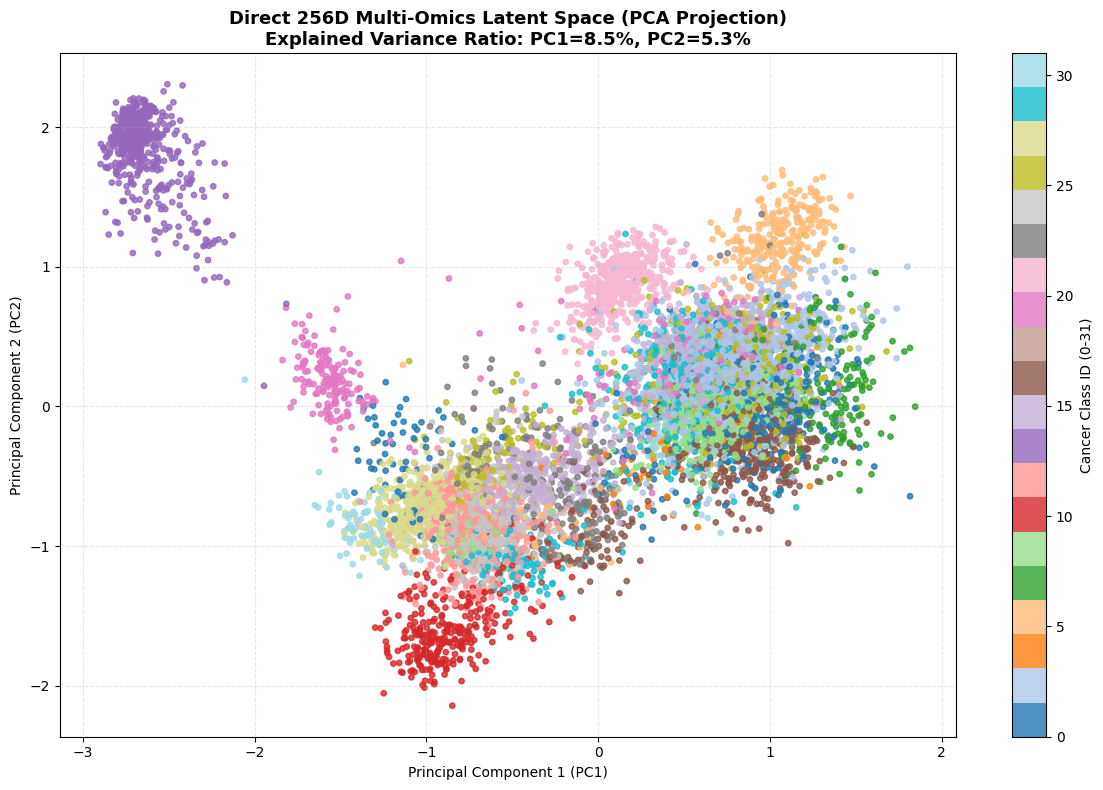

PCA plot successfully saved to ./customics_artifacts/latent_space_pca.png


In [7]:
# 1. Load trained latent embeddings from Fold 1
latent_path = os.path.join(ARTIFACT_DIR, "embeddings", "latent_fold_1.npy")
latent_256d = np.load(latent_path)

# 2. Project 256D representations down to 2D using PCA
pca = PCA(n_components=2, random_state=SEED)
latent_2d = pca.fit_transform(latent_256d)

# 3. Plot latent space scatter colored by cancer class
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    latent_2d[:, 0], 
    latent_2d[:, 1], 
    c=y, 
    cmap="tab20", 
    s=15, 
    alpha=0.8
)

plt.colorbar(scatter, label="Cancer Class ID (0-31)")
plt.title(
    f"Direct 256D Multi-Omics Latent Space (PCA Projection)\n"
    f"Explained Variance Ratio: PC1={pca.explained_variance_ratio_[0]*100:.1f}%, "
    f"PC2={pca.explained_variance_ratio_[1]*100:.1f}%", 
    fontsize=13, fontweight="bold"
)
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()

# 4. Save and display plot
plt.savefig(os.path.join(ARTIFACT_DIR, "latent_space_pca.png"), dpi=300)
plt.show()

print(f"PCA plot successfully saved to {ARTIFACT_DIR}/latent_space_pca.png")